# Final spatial distribution: Monte Carlo versus PDE solver

Two instantaneous-burst tests at $t=10^8$ yr: **pure diffusion** and **diffusion plus constant vertical advection**. The PDE calculation directly links `../cpp/energy_loss/spatial_solver.cpp`, `field.cpp` and `initialization.cpp`; it does not replace that solver with an analytical reference. The dedicated driver and build file are `spatial_mc_pde.cpp` and `Makefile.spatial_mc_pde` in the MC project.

Reproduce from the project directory with `make -f Makefile.spatial_mc_pde run`, then run this notebook from the project directory or `output/`.

Both methods solve the spatial-only equation
$$\partial_t n=D\left[\frac1R\partial_R(R\partial_R n)+\partial_z^2n\right]-\partial_z(v_zn).$$
$D=10^{29}$ cm$^2$/s is spatially constant; $v_z=0$ or $300$ km/s. There is no rigidity/energy evolution, momentum operator, interaction, continuing injection, or radial wind.

The axisymmetric initial **volume density** is proportional to
$$n_0(R,z)=\exp\left[-\frac{(R-10\,{\rm kpc})^2+(z-50\,{\rm kpc})^2}{2(2\,{\rm kpc})^2}\right].$$
The domain is $0\le R\le100$ kpc, $0\le z\le150$ kpc: zero flux at the lower faces and absorbing outer faces. The source is far from the vertical boundaries, keeping finite-step MC reflection/absorption errors negligible for this test. This tests interior diffusion/advection, rather than boundary accuracy. Constant positive wind is imposed on all vertical faces except the zero-flux lower boundary.

MC uses 200,000 particles, 500 Gaussian-increment steps, and common initial positions and diffusion increments between the two cases. The PDE uses cell-averaged initial densities from exact Gaussian integrals, cylindrical finite-volume geometry, CN–ADI diffusion and PLM/Van Leer/SSPRK2 advection with Strang splitting. Base grid: 0.5 kpc, 200,000 yr; refinement: 0.25 kpc, 100,000 yr. Each diffusion substep is half the transport timestep.


In [8]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

folder = Path('spatial_mc_pde')
if not folder.is_dir():
    folder = Path('output/spatial_mc_pde')
mc_initial_file = folder / 'mc_initial.bin'
mc_files = [folder / 'mc_diffusion.bin', folder / 'mc_wind.bin']
pde_files = [folder / 'pde_diffusion.bin', folder / 'pde_wind.bin']
pde_fine_files = [folder / 'pde_diffusion_fine.bin', folder / 'pde_wind_fine.bin']
N_particles = 200000
T_end = 1e8                  # yr
D_cm2_s = 1e29
kpc_cm = 3.0856775814913673e21
yr2s = 31557600.0
D = D_cm2_s * yr2s / kpc_cm**2  # kpc^2/yr
v_z = 300.0 * 1e5 * yr2s / kpc_cm  # kpc/yr
R0, z0, sigma0 = 10.0, 50.0, 2.0  # kpc
R_max, z_max = 100.0, 150.0         # kpc
case_labels = ['Pure diffusion', r'Diffusion + $v_z=300$ km/s']
colors = ['#0072B2', '#D55E00']
plt.rcParams.update({'font.size': 13, 'axes.labelsize': 15,
                     'axes.titlesize': 15, 'xtick.labelsize': 12,
                     'ytick.labelsize': 12, 'figure.dpi': 120})
# Binary files have no header; confirm parameters against the saved run metadata.
parameters = {}
with open(folder / 'parameters.txt') as file:
    for line in file:
        name, value = line.split()
        parameters[name] = float(value)
assert parameters['N'] == N_particles
assert parameters['T_end_yr'] == T_end
assert np.isclose(parameters['D_kpc2_yr'], D, rtol=1e-12, atol=0)
assert np.isclose(parameters['vz_kpc_yr'], v_z, rtol=1e-12, atol=0)
assert parameters['R0_kpc'] == R0 and parameters['z0_kpc'] == z0
assert parameters['sigma0_kpc'] == sigma0
assert parameters['Rmax_kpc'] == R_max and parameters['zmax_kpc'] == z_max


## Load particle positions and finite-volume densities

MC: three native-endian float64 values per record, `(x, y, z)` in **kpc**. Absorbed particles are omitted; normalization always uses the injected count, not the survivor count.

PDE: six native-endian float64 values per record, `(R_low, R_high, z_low, z_high, probability_density, cell_volume)`. Density is in kpc$^{-3}$, volume in kpc$^3$. The writer loops over radial cells first, then vertical cells. Probabilities are density times cylindrical volume, with no fitted rescaling.


In [9]:
initial = np.fromfile(mc_initial_file, dtype='=f8').reshape(-1, 3)
assert initial.shape == (N_particles, 3)
mc_positions = []
pde_data = []
pde_fine_data = []
for k in range(2):
    positions = np.fromfile(mc_files[k], dtype='=f8').reshape(-1, 3)
    coarse = np.fromfile(pde_files[k], dtype='=f8').reshape(200, 300, 6)
    fine = np.fromfile(pde_fine_files[k], dtype='=f8').reshape(400, 600, 6)
    assert np.all(np.isfinite(positions))
    assert np.all(coarse[:, :, 4] >= 0) and np.all(fine[:, :, 4] >= 0)
    assert np.all(coarse[:, :, 5] > 0) and np.all(fine[:, :, 5] > 0)
    mc_positions.append(positions)
    pde_data.append(coarse)
    pde_fine_data.append(fine)
    print(case_labels[k])
    print('  MC surviving fraction:', len(positions) / N_particles)
    print('  PDE total probability:', np.sum(coarse[:, :, 4] * coarse[:, :, 5]))
    print('  Fine PDE probability:', np.sum(fine[:, :, 4] * fine[:, :, 5]))


Pure diffusion
  MC surviving fraction: 1.0
  PDE total probability: 0.9999999999999729
  Fine PDE probability: 1.0000000000001685
Diffusion + $v_z=300$ km/s
  MC surviving fraction: 1.0
  PDE total probability: 0.999999999999962
  Fine PDE probability: 1.0000000000001719


## Common spatial bins and numerical refinement

Use 2 kpc bins for comparison. `np.histogram2d` counts MC particles in each $(R,z)$ rectangle (rows are radial bins, columns vertical bins). PDE probabilities are summed over exactly the same rectangles, rather than interpolated at bin centers. Reshaping groups the fine cells belonging to each comparison bin; summation conserves their probability.

For the density maps, divide each bin probability by
$$\Delta V=\pi(R_{i+1}^2-R_i^2)(z_{j+1}-z_j).$$
The total variation distance is $\frac12\sum_i|p_i-q_i|$. MC–PDE distance includes sampling noise; coarse–fine PDE distance measures numerical sensitivity.


In [10]:
R_bins = np.arange(0.0, R_max + 1.0, 2.0)
z_bins = np.arange(0.0, z_max + 1.0, 2.0)
R_centers = 0.5 * (R_bins[:-1] + R_bins[1:])
z_centers = 0.5 * (z_bins[:-1] + z_bins[1:])
bin_volume = np.pi * (R_bins[1:]**2 - R_bins[:-1]**2)[:, None] * np.diff(z_bins)[None, :]
mc_counts = []
mc_probability = []
pde_probability = []
pde_fine_probability = []
for k in range(2):
    positions = mc_positions[k]
    R = np.sqrt(positions[:, 0]**2 + positions[:, 1]**2)
    counts = np.histogram2d(R, positions[:, 2], bins=[R_bins, z_bins])[0]
    assert counts.sum() == len(positions)
    coarse = pde_data[k]
    fine = pde_fine_data[k]
    coarse_mass = coarse[:, :, 4] * coarse[:, :, 5]
    fine_mass = fine[:, :, 4] * fine[:, :, 5]
    probability = np.sum(coarse_mass.reshape(50, 4, 75, 4), axis=(1, 3))
    fine_probability = np.sum(fine_mass.reshape(50, 8, 75, 8), axis=(1, 3))
    mc_counts.append(counts)
    mc_probability.append(counts / N_particles)
    pde_probability.append(probability)
    pde_fine_probability.append(fine_probability)
    print(case_labels[k])
    print('  MC/PDE total variation:', 0.5 * np.sum(np.abs(counts / N_particles - probability)))
    print('  Coarse/fine PDE total variation:', 0.5 * np.sum(np.abs(probability - fine_probability)))

    expected = N_particles * probability
    selected = expected >= 25
    residual = (counts[selected] - expected[selected]) / np.sqrt(expected[selected] * (1 - probability[selected]))
    print('  Well-populated-bin residual RMS:', np.sqrt(np.mean(residual**2)))

# Bin the saved initial particles with exactly the same geometry and weights.
initial_R = np.sqrt(initial[:, 0]**2 + initial[:, 1]**2)
initial_counts = np.histogram2d(initial_R, initial[:, 2], bins=[R_bins, z_bins])[0]
assert initial_counts.sum() == N_particles
initial_probability = initial_counts / N_particles


Pure diffusion
  MC/PDE total variation: 0.016948121772833585
  Coarse/fine PDE total variation: 0.00018542141459093272
  Well-populated-bin residual RMS: 1.0237041007267607
Diffusion + $v_z=300$ km/s
  MC/PDE total variation: 0.01621552935920104
  Coarse/fine PDE total variation: 0.0006438625955954698
  Well-populated-bin residual RMS: 1.0533666730673976


## Final axisymmetric volume-density maps

The initial MC distribution and final MC/PDE distributions use the same bins, injected-count normalization and logarithmic density color scale in both cases. The initial distribution is shared by the two experiments. The residual map shows
$$(N_{\rm MC}-N_{\rm expected})/\sqrt{N_{\rm particles}p(1-p)},\quad N_{\rm expected}=N_{\rm particles}p.$$
Only bins with at least 25 expected particles are displayed. Individual bin errors have binomial variance; bins are mutually correlated, so this map is a visual diagnostic rather than an independent-bin significance test.


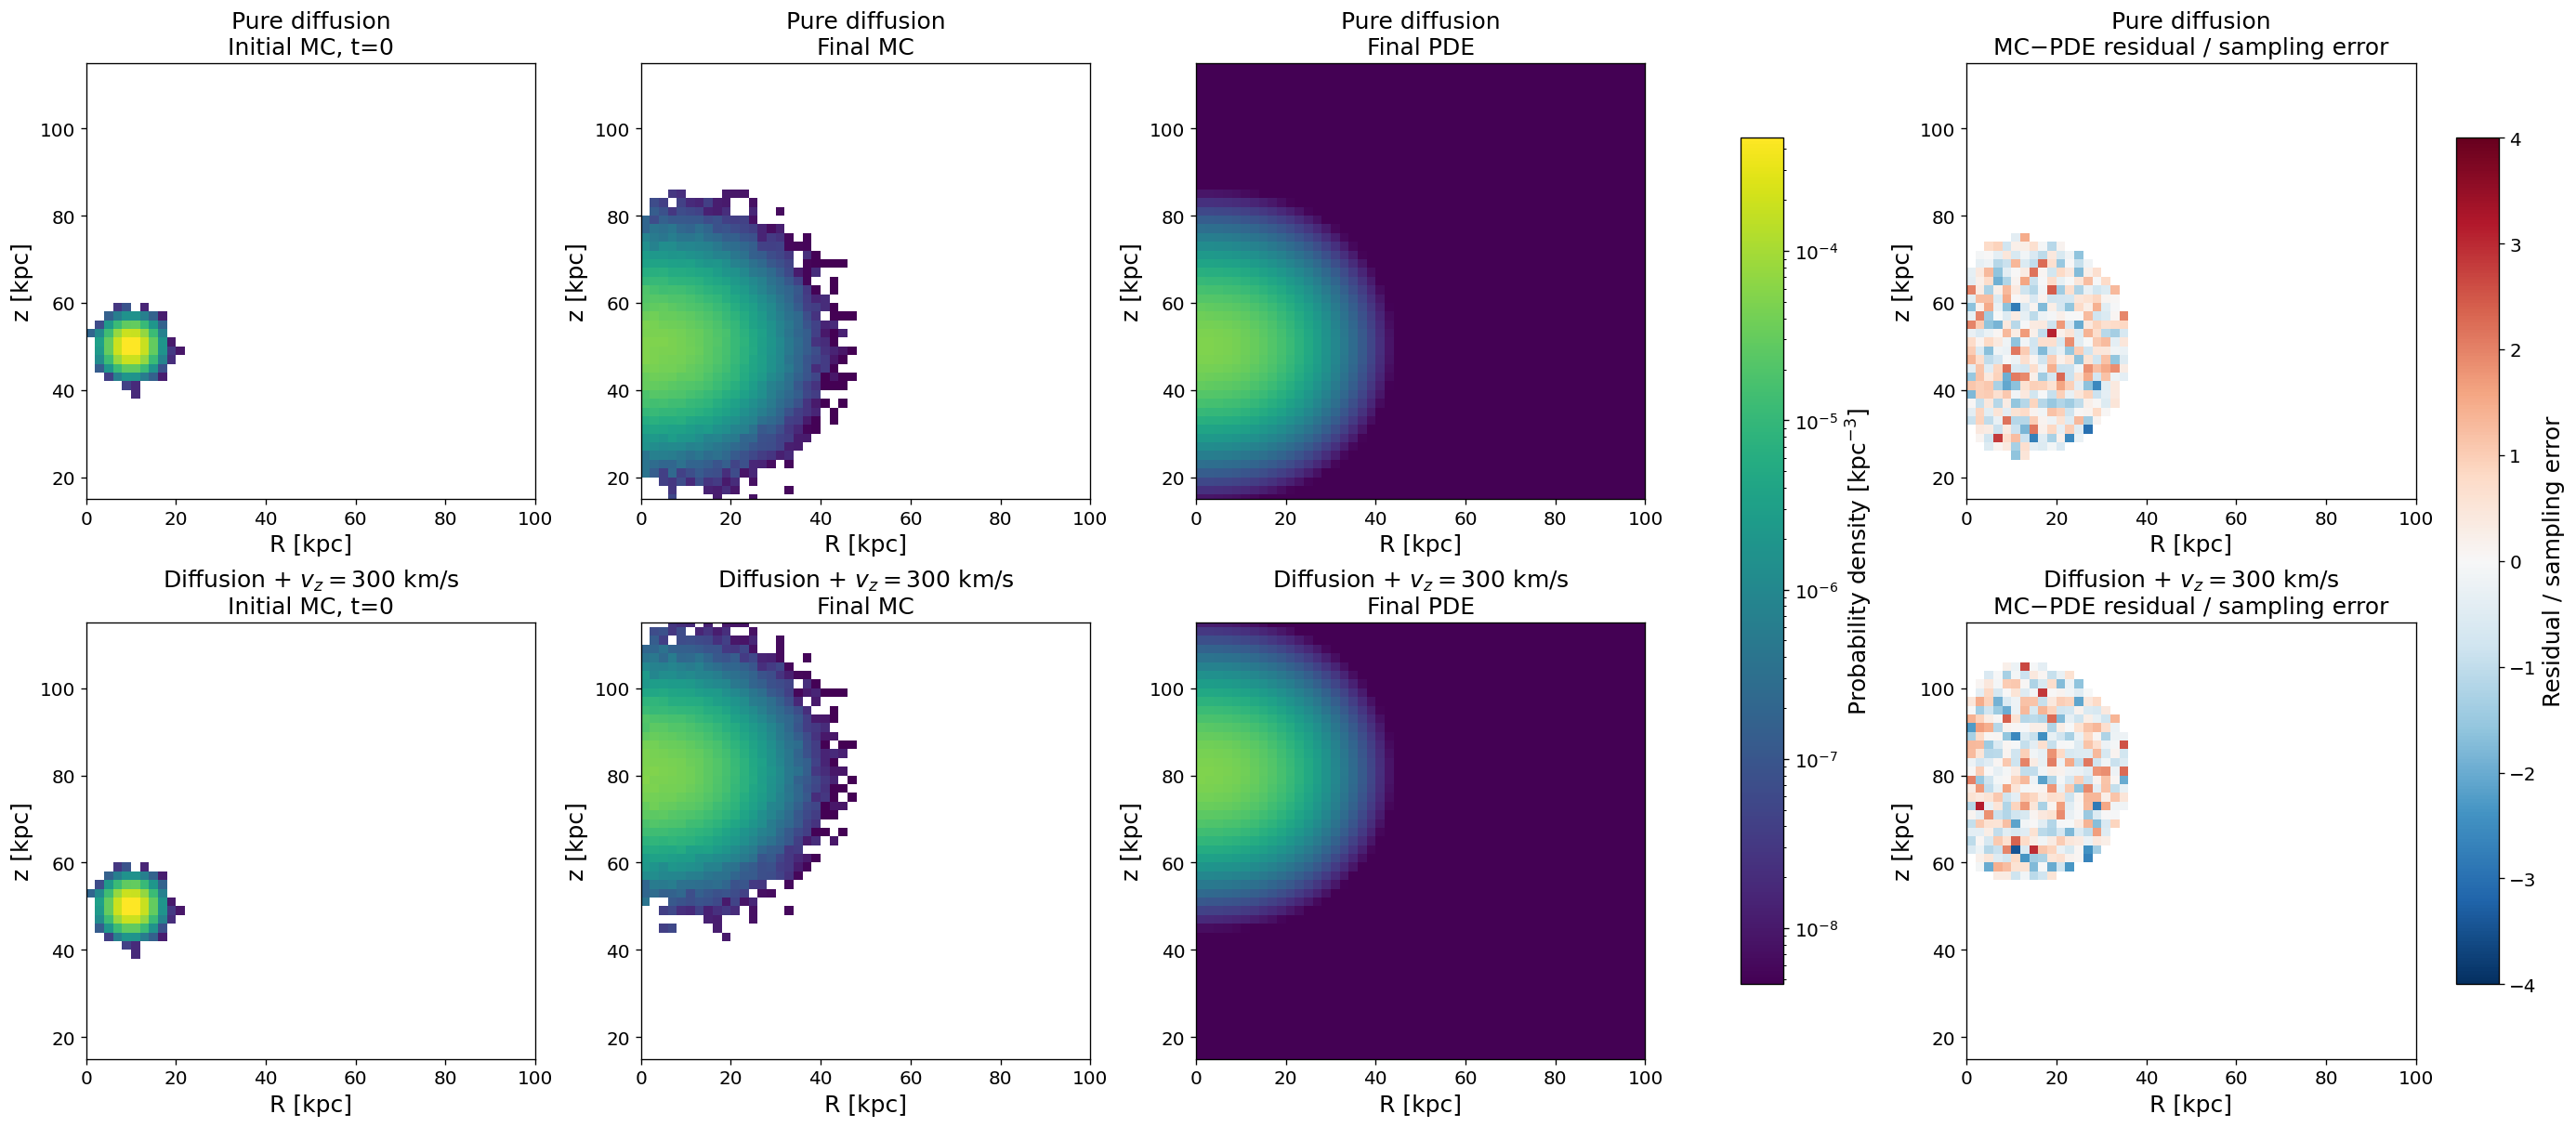

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(23, 10), layout='constrained')
maximum = max(np.max(p / bin_volume) for p in pde_probability + mc_probability + [initial_probability])
norm = LogNorm(vmin=maximum * 1e-5, vmax=maximum)
for k in range(2):
    for column, probability in enumerate([initial_probability, mc_probability[k], pde_probability[k]]):
        density = np.ma.masked_less_equal(probability / bin_volume, 0)
        mesh = axes[k, column].pcolormesh(R_bins, z_bins, density.T,
                                         norm=norm, cmap='viridis', shading='flat')
        axes[k, column].set_title(case_labels[k] + '\n' + ['Initial MC, t=0', 'Final MC', 'Final PDE'][column])
    expected = N_particles * pde_probability[k]
    variance = expected * (1 - pde_probability[k])
    residual = np.full(expected.shape, np.nan)
    selected = expected >= 25
    residual[selected] = (mc_counts[k][selected] - expected[selected]) / np.sqrt(variance[selected])
    residual_mesh = axes[k, 3].pcolormesh(R_bins, z_bins, residual.T,
                                          cmap='RdBu_r', vmin=-4, vmax=4, shading='flat')
    axes[k, 3].set_title(case_labels[k] + '\nMC−PDE residual / sampling error')
    for ax in axes[k]:
        ax.set_xlim(0, 100)
        ax.set_ylim(15, 115)
        ax.set_xlabel('R [kpc]')
        ax.set_ylabel('z [kpc]')
fig.colorbar(mesh, ax=axes[:, :3], label=r'Probability density [kpc$^{-3}$]', shrink=0.85)
fig.colorbar(residual_mesh, ax=axes[:, 3], label='Residual / sampling error', shrink=0.85)
plt.show()


## Radial and vertical probability distributions

These are probabilities per radial or vertical interval, $dP/dR$ and $dP/dz$, integrated over the other coordinate. In particular, $dP/dR$ includes the cylindrical volume factor; it is not the volume density $n(R,z)$. Error bars show the MC binomial sampling error. The PDE curves retain absolute normalization.


The green dotted curve shows the saved initial MC distribution, using the same bins and normalization as the final distributions.

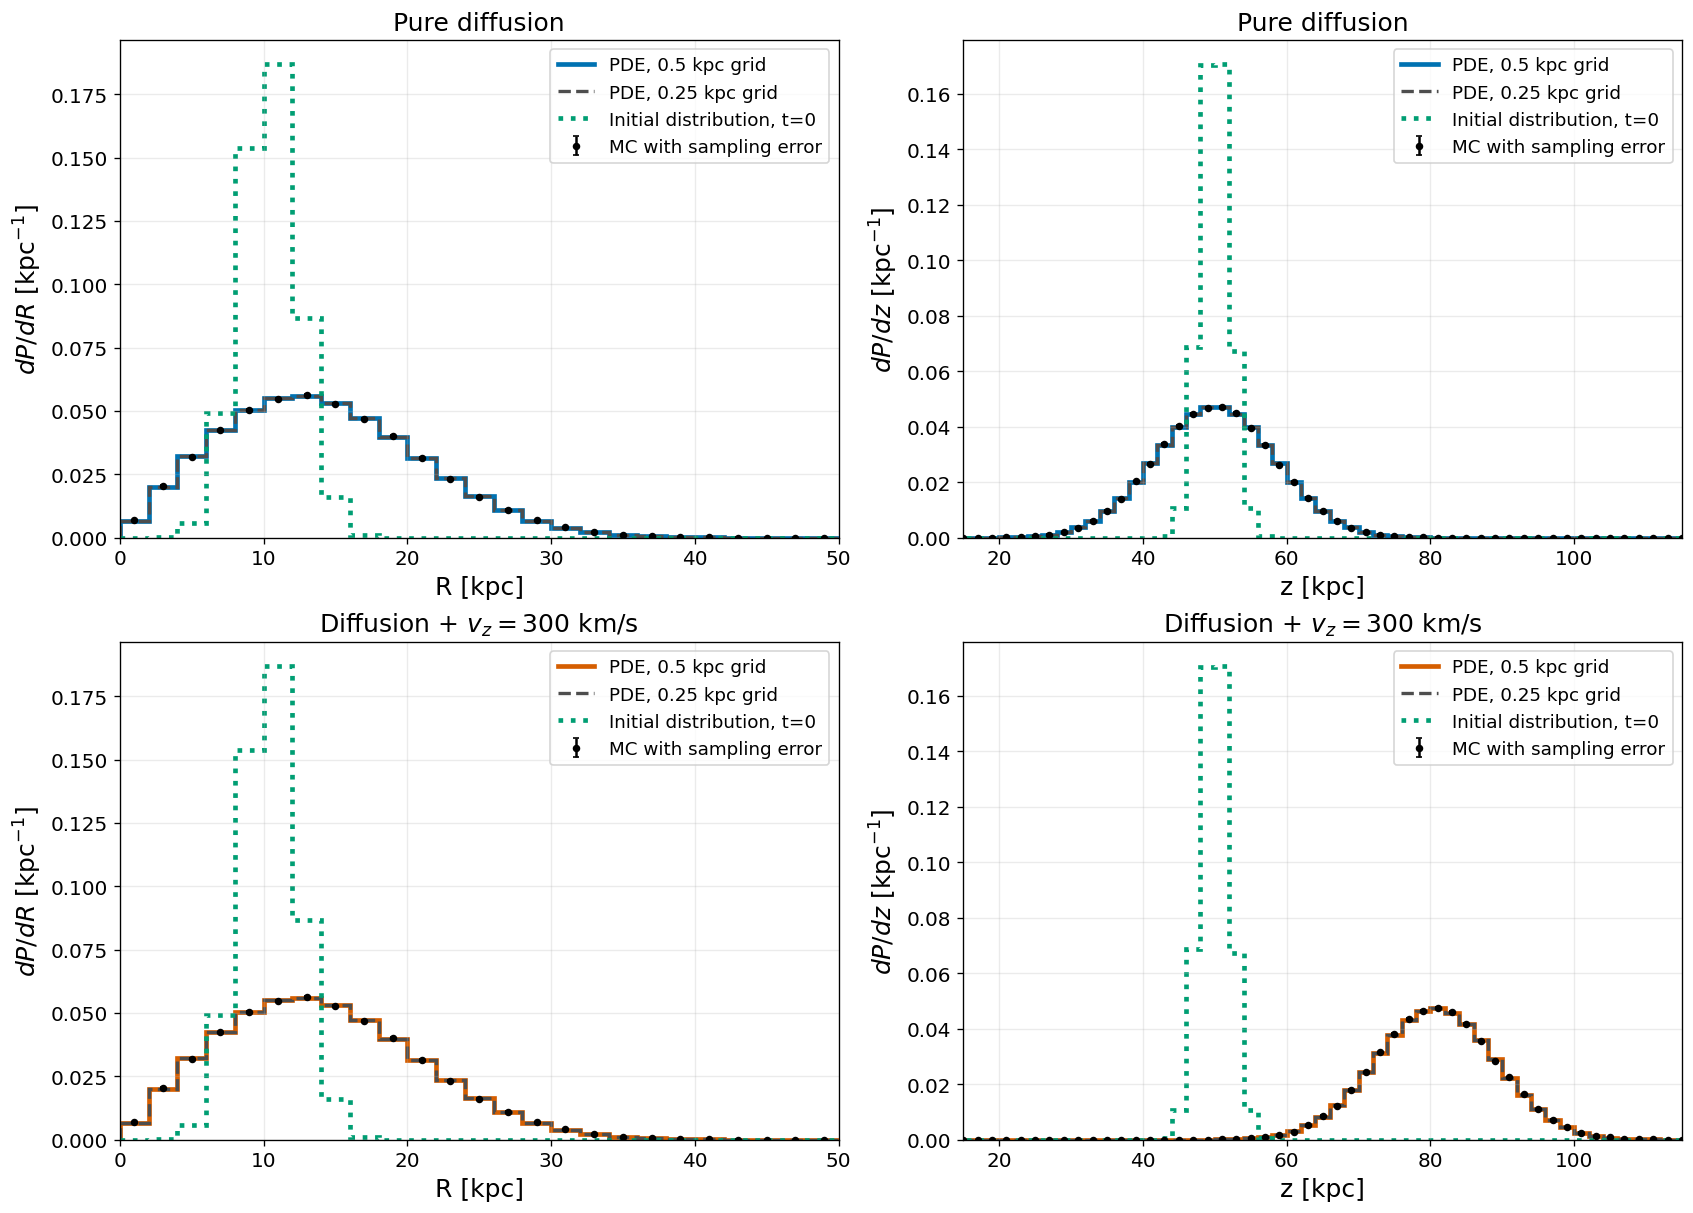

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), layout='constrained')
for k in range(2):
    for column in range(2):
        ax = axes[k, column]
        axis_to_sum = 1 if column == 0 else 0
        bins = R_bins if column == 0 else z_bins
        centers = R_centers if column == 0 else z_centers
        width = np.diff(bins)
        counts = np.sum(mc_counts[k], axis=axis_to_sum)
        observed = counts / N_particles
        predicted = np.sum(pde_probability[k], axis=axis_to_sum)
        predicted_fine = np.sum(pde_fine_probability[k], axis=axis_to_sum)
        initial_marginal = np.sum(initial_probability, axis=axis_to_sum)
        error = np.sqrt(observed * (1 - observed) / N_particles) / width
        ax.stairs(predicted / width, bins, color=colors[k], linewidth=2.8, label='PDE, 0.5 kpc grid')
        ax.stairs(predicted_fine / width, bins, color='0.3', linestyle='--', linewidth=2,
                  label='PDE, 0.25 kpc grid')
        ax.errorbar(centers, observed / width, yerr=error, color='black', fmt='o',
                    markersize=3.5, capsize=2, label='MC with sampling error')
        ax.stairs(initial_marginal / width, bins, color='#009E73',
                  linestyle=':', linewidth=2.8, label='Initial distribution, t=0')
        ax.set_xlim((0, 50) if column == 0 else (15, 115))
        ax.set_xlabel('R [kpc]' if column == 0 else 'z [kpc]')
        ax.set_ylabel(r'$dP/dR$ [kpc$^{-1}$]' if column == 0 else r'$dP/dz$ [kpc$^{-1}$]')
        ax.set_title(case_labels[k])
        ax.grid(alpha=0.25)
        ax.legend(fontsize=11)
plt.show()


## Moments and analytic checks

Far from the vertical boundaries, the expected vertical mean and variance are
$$\langle z\rangle=z_0+v_zt,\qquad \operatorname{Var}(z)=\sigma_0^2+2Dt.$$
Cartesian diffusion also gives $\langle R^2\rangle=\langle R_0^2\rangle+4Dt$. The radial source is weighted by $R$, so $\langle R_0^2\rangle$ is calculated from the actual injected particles rather than treating the radial Gaussian as a Cartesian Gaussian.

PDE moments use cell-averaged coordinate moments: $\langle z^2\rangle_{\rm cell}=(z_l^2+z_lz_h+z_h^2)/3$ and $\langle R^2\rangle_{\rm cell}=(R_l^2+R_h^2)/2$. The comparison of two MC cases uses shared random paths and is not a comparison of independent ensembles.


In [13]:
initial_R2 = initial[:, 0]**2 + initial[:, 1]**2
expected_z_variance = sigma0**2 + 2 * D * T_end
print('Expected diffusion width sqrt(2Dt) [kpc]:', np.sqrt(2 * D * T_end))
print('Expected wind displacement [kpc]:', v_z * T_end)
for k in range(2):
    positions = mc_positions[k]
    data = pde_data[k]
    mass = data[:, :, 4] * data[:, :, 5]
    total = np.sum(mass)
    z_center = 0.5 * (data[:, :, 2] + data[:, :, 3])
    z_second = (data[:, :, 2]**2 + data[:, :, 2] * data[:, :, 3] + data[:, :, 3]**2) / 3
    R_second = 0.5 * (data[:, :, 0]**2 + data[:, :, 1]**2)
    pde_mean_z = np.sum(mass * z_center) / total
    pde_variance_z = np.sum(mass * z_second) / total - pde_mean_z**2
    pde_mean_R2 = np.sum(mass * R_second) / total
    mc_mean_z = np.mean(positions[:, 2])
    mc_variance_z = np.var(positions[:, 2])
    mc_mean_R2 = np.mean(positions[:, 0]**2 + positions[:, 1]**2)
    expected_mean_z = z0 + k * v_z * T_end
    expected_R2 = np.mean(initial_R2) + 4 * D * T_end
    print('\n' + case_labels[k])
    print('                 MC           PDE          analytic interior reference')
    print(f'mean z [kpc]  {mc_mean_z:12.5f} {pde_mean_z:12.5f} {expected_mean_z:12.5f}')
    print(f'var z [kpc2]  {mc_variance_z:12.5f} {pde_variance_z:12.5f} {expected_z_variance:12.5f}')
    print(f'mean R2       {mc_mean_R2:12.5f} {pde_mean_R2:12.5f} {expected_R2:12.5f}')
    mean_se = np.std(positions[:, 2], ddof=1) / np.sqrt(N_particles)
    print('MC−PDE mean z / MC standard error:', (mc_mean_z - pde_mean_z) / mean_se)
    assert abs(mc_mean_z - pde_mean_z) < 5 * mean_se
    assert abs(pde_variance_z / expected_z_variance - 1) < 0.01


Expected diffusion width sqrt(2Dt) [kpc]: 8.14172512867254
Expected wind displacement [kpc]: 30.681364951370846

Pure diffusion
                 MC           PDE          analytic interior reference
mean z [kpc]      49.99468     50.00000     50.00000
var z [kpc2]      70.10359     70.32935     70.28769
mean R2          244.73219    244.66588    244.75096
MC−PDE mean z / MC standard error: -0.2843258445937668

Diffusion + $v_z=300$ km/s
                 MC           PDE          analytic interior reference
mean z [kpc]      80.67604     80.68110     80.68136
var z [kpc2]      70.10359     70.41039     70.28769
mean R2          244.73219    244.66588    244.75096
MC−PDE mean z / MC standard error: -0.2704060967259741
